# Estimación de la presión arterial

Este notebook implementa el modelo de regresión para estimar la presión arterial sistólica ( en mmHg) a partir de variables clínicas, demográficas y de hábitos de salud.
Corresponde al modelo **M02: Salud - Presión arterial estimada**.

## Importar librerías necesarias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')

## Cargar el conjunto de datos

In [2]:
bp_df = pd.read_excel('../data/raw/M01-M02-M03.xlsx', sheet_name='Presión Arterial')
print(f'Dimensiones del dataset: {bp_df.shape[0]} filas x {bp_df.shape[1]} columnas')
bp_df.head()

Dimensiones del dataset: 4240 filas x 15 columnas


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0


In [3]:
bp_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
dtypes: float64(9), int64(6)
memory usage: 497.0 KB


## Limpieza de datos

Examinamos los valores faltantes y aplicamos las transformaciones necesarias.

In [4]:
# Conteo de valores nulos por columna
nulls = bp_df.isna().sum()
print('Columnas con valores nulos:')
print(nulls[nulls > 0])

Columnas con valores nulos:
education     105
cigsPerDay     29
BPMeds         53
totChol        50
BMI            19
heartRate       1
glucose       388
dtype: int64


### Tratamiento de fumadores ( y )
Si la persona no fuma () y  es nulo, corresponde a 0 cigarrillos al día.

In [5]:
bp_df.loc[(bp_df['currentSmoker'] == 0) & (bp_df['cigsPerDay'].isna()), 'cigsPerDay'] = 0

### Imputación de variables numéricas y discretas
Para evitar distorsiones por valores atípicos (outliers), las variables continuas se imputan con la mediana, y las discretas con la moda.

In [6]:
# Imputación de la mediana en variables continuas
for col in ['cigsPerDay', 'totChol', 'BMI', 'heartRate', 'glucose']:
    bp_df[col] = bp_df[col].fillna(bp_df[col].median())

# Imputación de la moda en variables discretas
for col in ['education', 'BPMeds']:
    bp_df[col] = bp_df[col].fillna(bp_df[col].mode()[0])

print(f'Nulos restantes en el dataset: {bp_df.isna().sum().sum()}')

Nulos restantes en el dataset: 0


## Preparación de los datos

Se define la variable objetivo  (presión arterial sistólica) y el conjunto de características predictoras (excluyendo  para estimar la presión de forma no invasiva).

In [7]:
feature_cols = [
    'male', 'age', 'education', 'currentSmoker', 'cigsPerDay',
    'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes',
    'totChol', 'BMI', 'heartRate', 'glucose'
]
y = bp_df['sysBP']
X = bp_df[feature_cols]

# Separación en conjunto de entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalado de variables para modelos lineales
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Entrenamiento: {len(X_train)} registros  |  Prueba: {len(X_test)} registros')

Entrenamiento: 3392 registros  |  Prueba: 848 registros


## Funciones para evaluar el modelo

Métricas oficiales de regresión requeridas por la cátedra: MAE, MSE / RMSE y R².

In [8]:
def evaluar(y_real, y_pred):
    """Calcula métricas de evaluación de regresión."""
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_pred)
    return {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    }

resultados = {}

## Entrenamiento del modelo

### Modelo simple (Dummy Regressor)

In [9]:
base = DummyRegressor(strategy='mean')
base.fit(X_train, y_train)
resultados['Base'] = evaluar(y_test, base.predict(X_test))

### Modelo árbol de decisión (Decision Tree Regressor)

In [10]:
tree = DecisionTreeRegressor(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
resultados['Decision Tree'] = evaluar(y_test, tree.predict(X_test))

### Modelo de regresión lineal (Linear Regression)

In [11]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
resultados['Linear Regression'] = evaluar(y_test, lr.predict(X_test_scaled))

### Modelo Ridge (Ridge Regression)

In [12]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
resultados['Ridge'] = evaluar(y_test, ridge.predict(X_test_scaled))

### Modelo Random Forest

In [13]:
rf = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
resultados['Random Forest'] = evaluar(y_test, rf.predict(X_test))

### Modelo Gradient Boosting

In [14]:
gb = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
resultados['Gradient Boosting'] = evaluar(y_test, gb.predict(X_test))

## Comparación de modelos

Se ordenan los modelos por RMSE (menor error es mejor) y se reporta el R².

In [15]:
comparacion = pd.DataFrame(resultados).T.sort_values('RMSE', ascending=True)
comparacion.round(4)

,MAE,MSE,RMSE,R2
Ridge,10.8153,207.2467,14.3961,0.5320
Linear Regression,10.8157,207.2520,14.3962,0.5320
Gradient Boosting,10.8378,208.5858,14.4425,0.5289
Random Forest,10.9885,210.2440,14.4998,0.5252
Decision Tree,11.2999,218.7764,14.7911,0.5059
Base,16.0517,443.1180,21.0504,-0.0007


/tmp/ipykernel_312774/2285724459.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparacion.reset_index(), x='RMSE', y='index', ax=axes[0], palette='viridis')
/tmp/ipykernel_312774/2285724459.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparacion.reset_index(), x='R2', y='index', ax=axes[1], palette='magma')


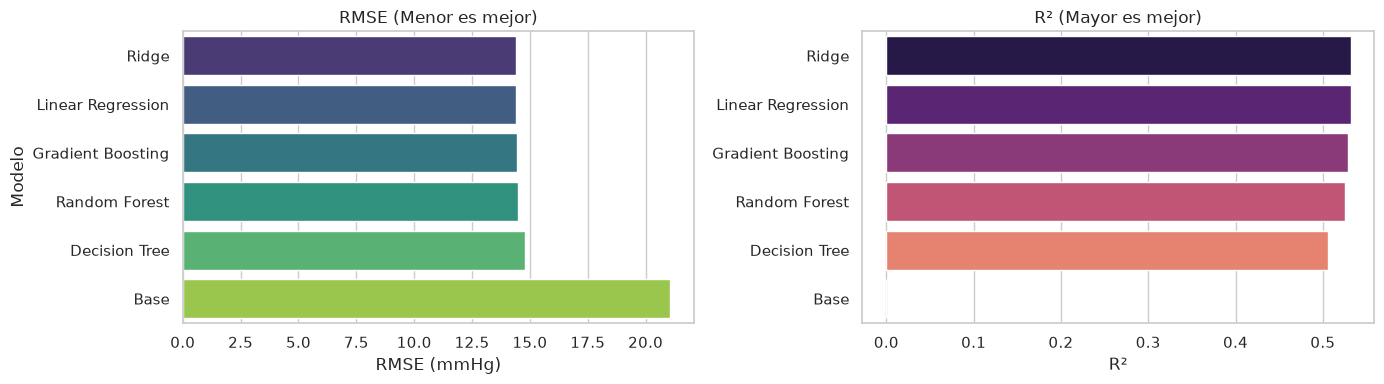

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=comparacion.reset_index(), x='RMSE', y='index', ax=axes[0], palette='viridis')
axes[0].set_title('RMSE (Menor es mejor)')
axes[0].set_ylabel('Modelo')
axes[0].set_xlabel('RMSE (mmHg)')

sns.barplot(data=comparacion.reset_index(), x='R2', y='index', ax=axes[1], palette='magma')
axes[1].set_title('R² (Mayor es mejor)')
axes[1].set_ylabel('')
axes[1].set_xlabel('R²')

plt.tight_layout()
plt.show()

## Exportar el modelo final

Exportamos el modelo con mejor desempeño (Ridge) junto con su escalador a la carpeta .

In [17]:
import joblib
from sklearn.pipeline import Pipeline

# Creamos un pipeline que combina escalador + modelo para facilitar el uso en el API
modelo_final = Pipeline([
    ('scaler', scaler),
    ('model', ridge)
])

# Exportamos el modelo con mejor desempeño
joblib.dump(modelo_final, '../models/blood_pressure_ridge_model.joblib')
print('Modelo exportado exitosamente en ../models/blood_pressure_ridge_model.joblib')

Modelo exportado exitosamente en ../models/blood_pressure_ridge_model.joblib


## Verificación de inferencia con paciente de muestra

In [18]:
# Prueba de carga e inferencia del modelo exportado
modelo_cargado = joblib.load('../models/blood_pressure_ridge_model.joblib')

paciente_ejemplo = pd.DataFrame([{
    'male': 1, 'age': 45, 'education': 3, 'currentSmoker': 0, 'cigsPerDay': 0,
    'BPMeds': 0, 'prevalentStroke': 0, 'prevalentHyp': 0, 'diabetes': 0,
    'totChol': 210, 'BMI': 25.0, 'heartRate': 72, 'glucose': 85
}])

pred = modelo_cargado.predict(paciente_ejemplo)[0]
print(f'Presión arterial sistólica estimada para el paciente: {pred:.2f} mmHg')

Presión arterial sistólica estimada para el paciente: 118.24 mmHg
